<a href="https://colab.research.google.com/github/Alv2606/Optativa_IA/blob/main/Pr%C3%A1ctica_2_3_teachable_machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Teachable Machine**

En esta práctica se debe exportar el modelo que se genera en Teachable Machine.

A la hora de exportar el modelo, se puede exportar para Tensorflow.

También viene un fragmento de código para usar el modelo:

```
from keras.models import load_model  # TensorFlow is required for Keras to work
from PIL import Image, ImageOps  # Install pillow instead of PIL
import numpy as np

# Disable scientific notation for clarity
np.set_printoptions(suppress=True)

# Load the model
model = load_model("keras_Model.h5", compile=False)

# Load the labels
class_names = open("labels.txt", "r").readlines()

# Create the array of the right shape to feed into the keras model
# The 'length' or number of images you can put into the array is
# determined by the first position in the shape tuple, in this case 1
data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

# Replace this with the path to your image
image = Image.open("<IMAGE_PATH>").convert("RGB")

# resizing the image to be at least 224x224 and then cropping from the center
size = (224, 224)
image = ImageOps.fit(image, size, Image.Resampling.LANCZOS)

# turn the image into a numpy array
image_array = np.asarray(image)

# Normalize the image
normalized_image_array = (image_array.astype(np.float32) / 127.5) - 1

# Load the image into the array
data[0] = normalized_image_array

# Predicts the model
prediction = model.predict(data)
index = np.argmax(prediction)
class_name = class_names[index]
confidence_score = prediction[0][index]

# Print prediction and confidence score
print("Class:", class_name[2:], end="")
print("Confidence Score:", confidence_score)

```

**Tarea**: subir 3 imágenes propias (una clara, una ambigua, una que no pertenezca a ninguna categoría) y anotar qué predice y con qué confianza.

## Solución de la práctica

Ejecuta las celdas **de arriba abajo**. Necesitas los archivos `keras_Model.h5` (o `keras_model.h5`) y `labels.txt` exportados desde tu proyecto de Teachable Machine. Después sube una fotografía en cada prueba. **No se inventan las predicciones**: Colab las calculará con tu modelo.

### 1. Preparar las librerías (Keras clásico)

In [ ]:
# Instalamos la versión de compatibilidad que necesita el modelo .h5
%pip -q install tf-keras

import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras
from PIL import Image, ImageOps
import numpy as np
from google.colab import files
from IPython.display import display

print("TensorFlow:", tf.__version__)
print("TF-Keras:", keras.__version__)

TensorFlow: 2.21.0
TF-Keras: 2.21.0


### 2. Subir el modelo y las etiquetas

Descarga el modelo desde **Teachable Machine → Exportar modelo → TensorFlow → Keras**. Descomprime el ZIP y sube **los dos archivos** `.h5` y `labels.txt` al ejecutar esta celda.

In [ ]:
# Subir keras_Model.h5 (o keras_model.h5) y labels.txt
print("Selecciona el modelo .h5 y labels.txt")
archivos = files.upload()

Selecciona el modelo .h5 y labels.txt


Saving labels.txt to labels.txt


In [ ]:
# Cargar el modelo entrenado y los nombres de sus categorías
modelos = [nombre for nombre in os.listdir() if nombre.lower().endswith(".h5")]
if not modelos:
    raise FileNotFoundError("Falta el archivo .h5. Súbelo en la celda anterior.")
if not os.path.exists("labels.txt"):
    raise FileNotFoundError("Falta labels.txt. Súbelo en la celda anterior.")

modelo = keras.models.load_model(modelos[0], compile=False)
with open("labels.txt", "r", encoding="utf-8") as archivo:
    etiquetas = [linea.strip().split(" ", 1)[-1] for linea in archivo]

print("Modelo cargado correctamente")
print("Categorías:", etiquetas)

Modelo cargado correctamente
Categorías: ['Botella de agua', 'Mando de televisión']


### 3. Función para clasificar una fotografía

La función prepara cualquier imagen de la misma manera que el ejemplo del profesor: la convierte a RGB, adapta su tamaño a 224 × 224 y normaliza los píxeles entre -1 y 1. Después el modelo devuelve sus puntuaciones.

In [ ]:
def clasificar_imagen(nombre_archivo):
    imagen = Image.open(nombre_archivo).convert("RGB")
    display(imagen)

    # Preparar la imagen para el modelo
    imagen = ImageOps.fit(imagen, (224, 224), Image.Resampling.LANCZOS)
    imagen_array = np.asarray(imagen)
    datos = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)
    datos[0] = (imagen_array.astype(np.float32) / 127.5) - 1

    # Realizar la predicción
    prediccion = modelo.predict(datos, verbose=0)
    indice = np.argmax(prediccion[0])
    clase = etiquetas[indice]
    confianza = float(prediccion[0][indice])

    print("Clase predicha:", clase)
    print(f"Confianza: {confianza * 100:.2f}%")
    print("Puntuaciones de todas las categorías:")
    for i in range(len(etiquetas)):
        print(f"  {etiquetas[i]}: {prediccion[0][i] * 100:.2f}%")

    return clase, confianza

### 4. Imagen que pertenece claramente a una categoría

Sube **una foto propia** en la que se vea claramente uno de los objetos de tu modelo. Por ejemplo, si entrenaste las categorías *botella* y *mando*, sube una foto de una botella sola.

Sube SOLO la imagen clara


Saving H2O500.jpg to H2O500.jpg


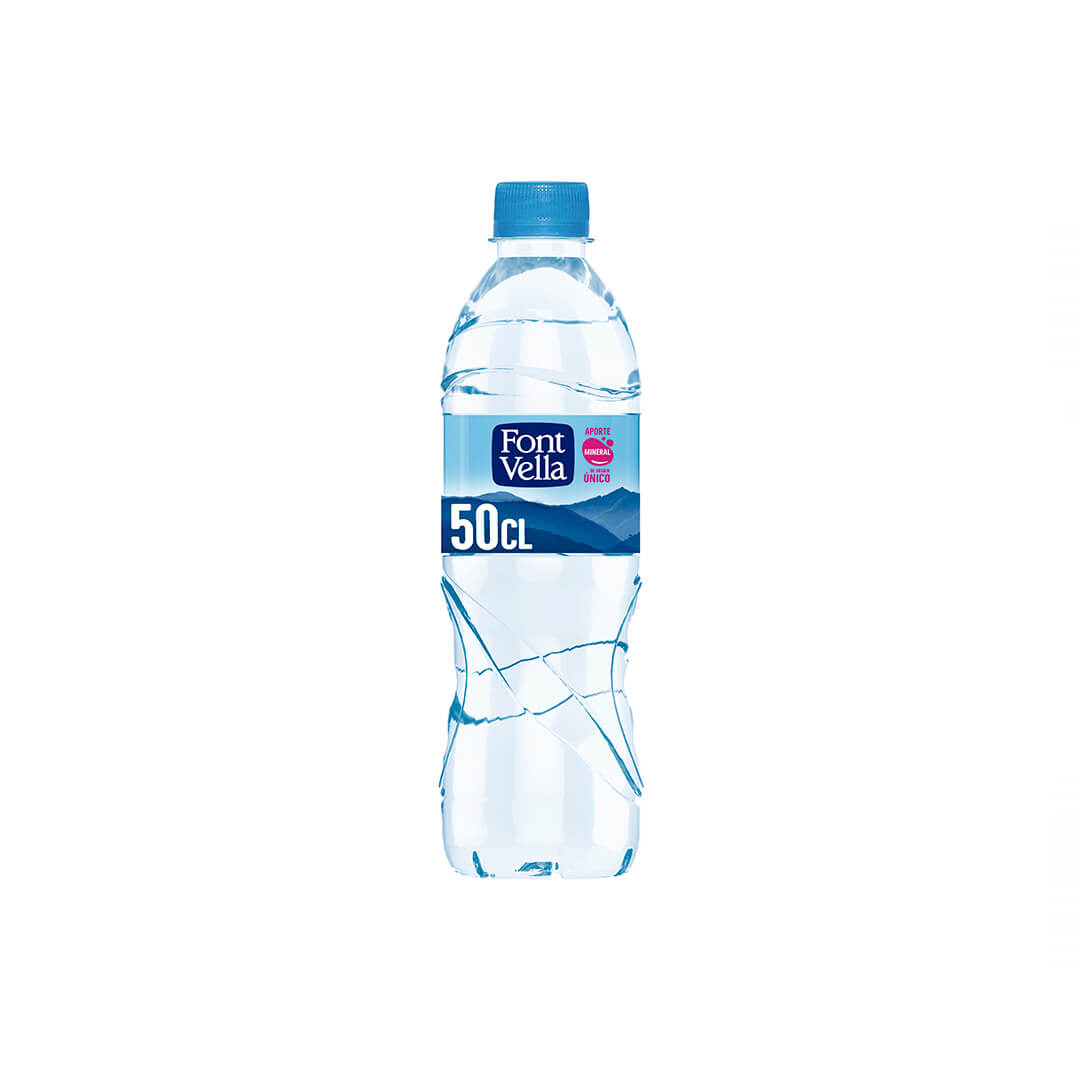

Clase predicha: Botella de agua
Confianza: 98.62%
Puntuaciones de todas las categorías:
  Botella de agua: 98.62%
  Mando de televisión: 1.38%


In [7]:
# Clasificación con una imagen clara
print("Sube SOLO la imagen clara")
subidos = files.upload()
nombre_clara = list(subidos.keys())[0]
clase_clara, confianza_clara = clasificar_imagen(nombre_clara)

### 5. Imagen ambigua

Sube una foto propia difícil de clasificar, por ejemplo con los dos objetos de tu modelo en una misma imagen.

Sube SOLO la imagen ambigua


Saving botella y mando.png to botella y mando.png


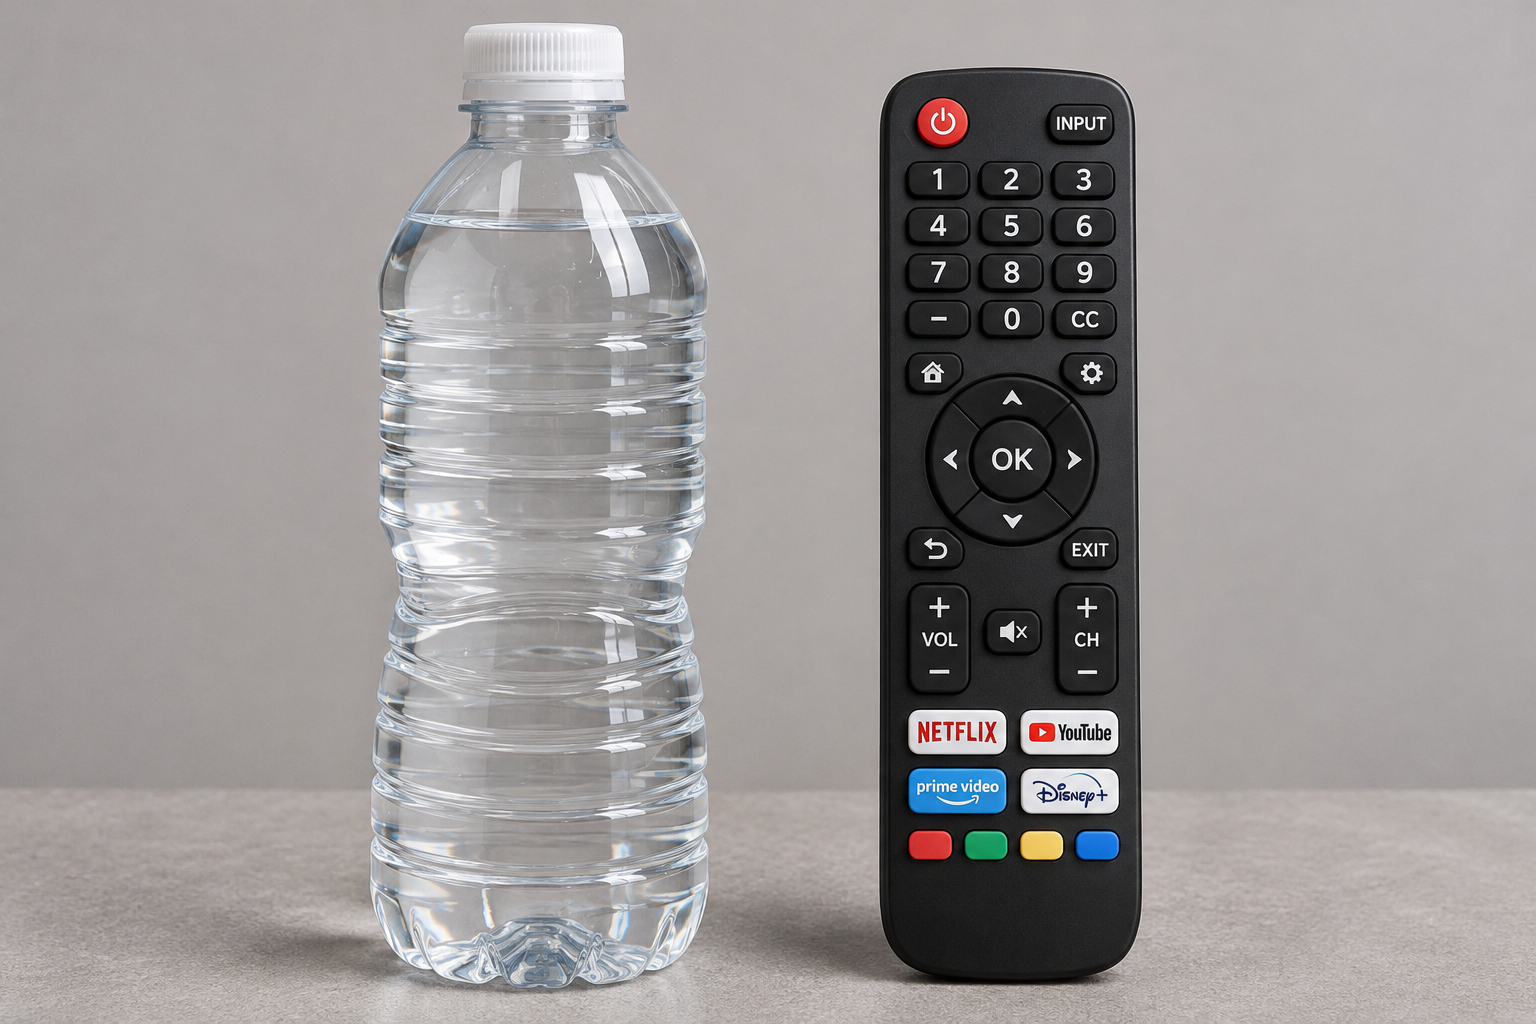

Clase predicha: Botella de agua
Confianza: 98.39%
Puntuaciones de todas las categorías:
  Botella de agua: 98.39%
  Mando de televisión: 1.61%


In [8]:
# Clasificación con una imagen ambigua
print("Sube SOLO la imagen ambigua")
subidos = files.upload()
nombre_ambigua = list(subidos.keys())[0]
clase_ambigua, confianza_ambigua = clasificar_imagen(nombre_ambigua)

### 6. Imagen que no pertenece a ninguna categoría

Sube una foto propia de un objeto que **no hayas usado como clase** durante el entrenamiento (por ejemplo, una taza si tus categorías son botella y mando).

Sube SOLO una imagen que no pertenezca a ninguna categoría


Saving taza.jpg to taza.jpg


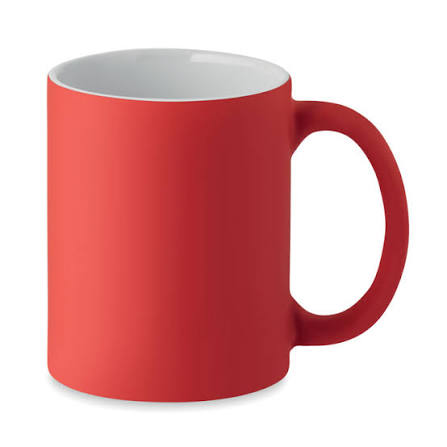

Clase predicha: Botella de agua
Confianza: 92.74%
Puntuaciones de todas las categorías:
  Botella de agua: 92.74%
  Mando de televisión: 7.26%


In [10]:
# Clasificación con una imagen de otra categoría
print("Sube SOLO una imagen que no pertenezca a ninguna categoría")
subidos = files.upload()
nombre_ninguna = list(subidos.keys())[0]
clase_ninguna, confianza_ninguna = clasificar_imagen(nombre_ninguna)

### 7. Informe de las tres pruebas

Al ejecutar esta celda aparecerán las predicciones **reales** del modelo y sus puntuaciones.

In [11]:
print("INFORME DE RESULTADOS")
print("---------------------")
print(f"1. Imagen clara: {clase_clara} - {confianza_clara * 100:.2f}%")
print(f"2. Imagen ambigua: {clase_ambigua} - {confianza_ambigua * 100:.2f}%")
print(f"3. Imagen de otra categoría: {clase_ninguna} - {confianza_ninguna * 100:.2f}%")

INFORME DE RESULTADOS
---------------------
1. Imagen clara: Botella de agua - 98.62%
2. Imagen ambigua: Botella de agua - 98.39%
3. Imagen de otra categoría: Botella de agua - 92.74%


### 8. ¿Cómo se usa el modelo exportado? ¿Cómo se comporta?

El modelo se ha entrenado previamente en Teachable Machine con imágenes de varias categorías. Al exportarlo para TensorFlow/Keras, obtenemos un archivo `.h5` que contiene el modelo entrenado y un archivo `labels.txt` con los nombres de las categorías.

Para usarlo en Python, cargamos ambos archivos. Después abrimos una fotografía, la convertimos a RGB, la redimensionamos a **224 × 224 píxeles** y normalizamos sus valores. Con `modelo.predict()` obtenemos las puntuaciones que asigna a cada categoría y con `np.argmax()` elegimos la de mayor puntuación.

Al probar una imagen clara, esperamos que el modelo reconozca la categoría correcta. En una imagen ambigua, puede tener dudas o confundir categorías. Si la imagen no pertenece a ninguna de las clases que aprendió, **seguirá escogiendo una de las clases disponibles**, porque no tiene una clase de «ninguna» a menos que la hayamos entrenado. Por eso una puntuación alta no garantiza que haya acertado.

**Conclusión:** el modelo puede clasificar imágenes que no ha visto antes, pero su comportamiento depende de las imágenes usadas en el entrenamiento y de lo parecida que sea la foto de prueba a esas imágenes. Los resultados concretos de las tres pruebas aparecen en el informe de la celda anterior.